Author: Aparajita Nath

First created: 27 October 2026

Product: a simple monitoring report: performance by segment and a clearly labelled simulated input shift

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import roc_auc_score
import helpers as h

pd.set_option("display.max_columns", 30)

## 5. Monitoring

### 5.1 Performance by segment

The logistic regression is monitored, because it is the simplest and most transparent of the three models. Its predictions on the held-out test set are compared across segments of loan duration and applicant age. For each segment the table shows the number of cases and bad credits, the observed bad rate, the average predicted PD and the AUC. The AUC is shown only when a segment has at least 10 bad and 10 good cases, because smaller groups give unstable estimates.

In [2]:
X_train, X_test, y_train, y_test = h.load_split()
lr = joblib.load(h.MODELS / "LR.joblib")
lr_pd = lr.predict_proba(X_test)[:, 1]
MIN_PER_CLASS = 10

def segment_table(labels, name):
    df = pd.DataFrame({"segment": labels.astype(str).to_numpy(), "bad": y_test.to_numpy(), "pd": lr_pd})
    rows = []
    for seg in [str(c) for c in labels.cat.categories]:
        g = df[df["segment"] == seg]
        bad, good = int(g["bad"].sum()), int((1 - g["bad"]).sum())
        auc = roc_auc_score(g["bad"], g["pd"]) if min(bad, good) >= MIN_PER_CLASS else np.nan
        rows.append({"dimension": name, "segment": seg, "cases": len(g), "bad_cases": bad,
                     "observed_bad_rate": g["bad"].mean(), "mean_predicted_pd": g["pd"].mean(), "roc_auc": auc})
    return pd.DataFrame(rows)

duration_seg = pd.cut(X_test["duration"], bins=[0, 12, 24, np.inf],
                      labels=["Up to 12 months", "13-24 months", "Over 24 months"])
age_seg = pd.cut(X_test["age"], bins=[0, 29, 44, np.inf], labels=["Under 30", "30-44", "45 and over"])
segments = pd.concat([segment_table(duration_seg, "Loan duration"),
                      segment_table(age_seg, "Applicant age")], ignore_index=True)
segments.to_csv(h.OUTPUTS / "segment_metrics.csv", index=False)
segments.round(3)

,dimension,segment,cases,bad_cases,observed_bad_rate,mean_predicted_pd,roc_auc
0,Loan duration,Up to 12 months,100,18,0.180,0.229,0.807
1,Loan duration,13-24 months,132,39,0.295,0.294,0.695
2,Loan duration,Over 24 months,68,33,0.485,0.449,0.743
3,Applicant age,Under 30,125,48,0.384,0.355,0.808
4,Applicant age,30-44,121,30,0.248,0.257,0.730
5,Applicant age,45 and over,54,12,0.222,0.313,0.722


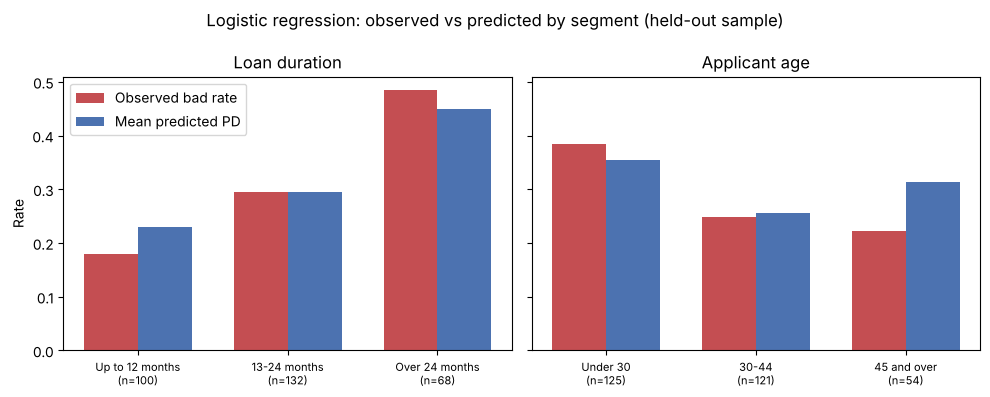

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, dim in zip(axes, ["Loan duration", "Applicant age"]):
    s = segments[segments["dimension"] == dim]
    x = np.arange(len(s))
    ax.bar(x - 0.18, s["observed_bad_rate"], 0.36, label="Observed bad rate", color="#c44e52")
    ax.bar(x + 0.18, s["mean_predicted_pd"], 0.36, label="Mean predicted PD", color="#4c72b0")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{a}\n(n={n})" for a, n in zip(s["segment"], s["cases"])], fontsize=8)
    ax.set_title(dim)
axes[0].set_ylabel("Rate")
axes[0].legend()
fig.suptitle("Logistic regression: observed vs predicted by segment (held-out sample)")
fig.tight_layout()
fig.savefig(h.FIGURES / "segment_calibration.png", dpi=160)
plt.show()

### 5.2 Simulated input shift (not real deterioration)

The data are a single historical snapshot with no time dimension, so real model deterioration cannot be observed. The exercise below is a **simulation**: loan durations in a copy of the test set are multiplied by 1.25 and the fitted logistic regression is re-scored. It shows how a monitoring check responds when the inputs move. It is not retraining, not observed deterioration and not a stress test.

The Population Stability Index (PSI) compares the score distribution before and after the change, on 10 bins fixed from the baseline scores: PSI = sum over bins of (share after - share before) x ln(share after / share before). Common rules of thumb read below 0.1 as little change and above 0.25 as a large change. These are conventions, not validated thresholds.

SIMULATED: duration x 1.25
Mean predicted PD, baseline: 0.308
Mean predicted PD, shifted:  0.329
PSI of scores:               0.026


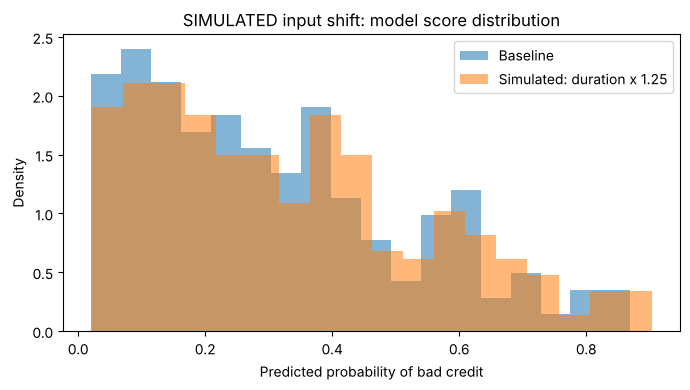

In [4]:
shifted = X_test.copy()
shifted["duration"] = shifted["duration"] * 1.25
shifted_pd = lr.predict_proba(shifted)[:, 1]

print("SIMULATED: duration x 1.25")
print(f"Mean predicted PD, baseline: {lr_pd.mean():.3f}")
print(f"Mean predicted PD, shifted:  {shifted_pd.mean():.3f}")
print(f"PSI of scores:               {h.psi(lr_pd, shifted_pd):.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(lr_pd, bins=18, alpha=0.55, density=True, label="Baseline")
ax.hist(shifted_pd, bins=18, alpha=0.55, density=True, label="Simulated: duration x 1.25")
ax.set(xlabel="Predicted probability of bad credit", ylabel="Density",
       title="SIMULATED input shift: model score distribution")
ax.legend()
fig.tight_layout()
fig.savefig(h.FIGURES / "simulated_shift.png", dpi=160)
plt.show()

### 5.3 Monitoring summary

In [5]:
metrics = pd.read_csv(h.OUTPUTS / "model_metrics.csv", index_col=0)
summary = pd.DataFrame({
    "item": ["Test cases", "Observed bad rate (test)",
             "Logistic regression: ROC-AUC", "Logistic regression: Gini", "Logistic regression: Brier score",
             "SIMULATED duration x 1.25: PSI of scores",
             "SIMULATED duration x 1.25: change in mean predicted PD"],
    "value": [len(y_test), y_test.mean(),
              metrics.loc["Logistic regression", "roc_auc"], metrics.loc["Logistic regression", "gini"],
              metrics.loc["Logistic regression", "brier_score"],
              h.psi(lr_pd, shifted_pd), shifted_pd.mean() - lr_pd.mean()],
}).set_index("item")
summary.to_csv(h.OUTPUTS / "monitoring_summary.csv")
summary.round(3)

,value
item,
Test cases,300.000
Observed bad rate (test),0.300
Logistic regression: ROC-AUC,0.768
Logistic regression: Gini,0.535
Logistic regression: Brier score,0.169
SIMULATED duration x 1.25: PSI of scores,0.026
SIMULATED duration x 1.25: change in mean predicted PD,0.022


### 5.4 What the report shows

- **Segments:** the observed bad rate rises with loan duration (18%, 30%, 49%) and the logistic regression follows it (predicted 23%, 29%, 45%). It predicts slightly too high for the shortest loans and slightly too low for the longest. For applicants aged 45 and over it predicts 31% against 22% observed, but this group has only 54 cases and 12 bad credits. The segment AUCs range from 0.70 to 0.81, and differences between segments are within what small groups can produce.
- **Simulated shift:** lengthening durations by 25% raises the mean predicted PD from 0.308 to 0.329 and gives a score PSI of 0.026, which is small by the usual rule of thumb. This is a simulation, not observed deterioration.

## 6. Limitations

- The data are a small historical snapshot (1,000 cases, 1973-1975) with no time dimension. Month-by-month monitoring or real model deterioration cannot be assessed.
- Bad credits are over-sampled, so the 30% bad share and the predicted PDs are not portfolio default rates.
- The test set has 300 cases and 90 bad credits. AUC intervals are wide and segment results are uncertain, especially in small groups.
- One random split was used for the test set. Repeating the split or using nested cross-validation would give a steadier comparison.
- The inputs include applicant sex and foreign-worker status. A model used for real lending today could not use them. They are kept here because they are part of the public dataset.
- Model governance checks (documentation, stability over time, benchmarking, challenger review, intended use) go well beyond what is shown here.
- This project is for learning and method comparison, not for lending decisions.